In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# Load the cleaned cafe sales dataset
csv_path = Path("../Data/cleaned_cafe_sales.csv")
df = pd.read_csv(csv_path)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())

Dataset loaded successfully!
Dataset shape: (10000, 8)


,Transaction ID,Item,Quantity,Price Per Unit,Total Spent,Payment Method,Location,Transaction Date
0,TXN_1961373,Coffee,2.0,2.0,4.0,Credit Card,Takeaway,2023-09-08
1,TXN_4977031,Cake,4.0,3.0,12.0,Cash,In-store,2023-05-16
2,TXN_4271903,Cookie,4.0,1.0,4.0,Credit Card,In-store,2023-07-19
3,TXN_7034554,Salad,2.0,5.0,10.0,Unknown,Unknown,2023-04-27
4,TXN_3160411,Coffee,2.0,2.0,4.0,Digital Wallet,In-store,2023-06-11


In [2]:
# Dataset quality checks
print("Dataset Information:")
df.info()

print("\nMissing values in each column:")
display(df.isnull().sum().to_frame("Missing Values"))

print("\nDuplicate rows:", df.duplicated().sum())

print("\nSummary Statistics:")
display(df.describe(include="all").T)

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Transaction ID    10000 non-null  object 
 1   Item              10000 non-null  object 
 2   Quantity          9962 non-null   float64
 3   Price Per Unit    9962 non-null   float64
 4   Total Spent       9960 non-null   float64
 5   Payment Method    10000 non-null  object 
 6   Location          10000 non-null  object 
 7   Transaction Date  9540 non-null   object 
dtypes: float64(3), object(5)
memory usage: 625.1+ KB

Missing values in each column:


,Missing Values
Transaction ID,0
Item,0
Quantity,38
Price Per Unit,38
Total Spent,40
Payment Method,0
Location,0
Transaction Date,460



Duplicate rows: 0

Summary Statistics:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Transaction ID,10000,10000,TXN_1961373,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Item,10000,9,Juice,1171,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Quantity,9962.0,NaN,NaN,NaN,3.025597,1.420181,1.0,2.0,3.0,4.0,5.0
Price Per Unit,9962.0,NaN,NaN,NaN,2.947902,1.279759,1.0,2.0,3.0,4.0,5.0
Total Spent,9960.0,NaN,NaN,NaN,8.930924,6.004475,1.0,4.0,8.0,12.0,25.0
Payment Method,10000,4,Unknown,3178,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Location,10000,3,Unknown,3961,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Transaction Date,9540,365,2023-02-06,40,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [3]:
# Overall sales summary
print("Total Revenue:", round(df["Total Spent"].sum(), 2))
print("Total Quantity Sold:", df["Quantity"].sum())
print("Total Transactions:", df["Transaction ID"].nunique())

# Revenue by item
revenue_by_item = (
    df.groupby("Item")["Total Spent"]
      .sum()
      .sort_values(ascending=False)
)

print("\nRevenue by Item:")
display(revenue_by_item.to_frame("Revenue"))

# Quantity sold by item
quantity_by_item = (
    df.groupby("Item")["Quantity"]
      .sum()
      .sort_values(ascending=False)
)

print("\nQuantity Sold by Item:")
display(quantity_by_item.to_frame("Quantity Sold"))

Total Revenue: 88952.0
Total Quantity Sold: 30141.0
Total Transactions: 10000

Revenue by Item:


,Revenue
Item,
Salad,17320.0
Sandwich,13664.0
Smoothie,13320.0
Juice,10509.0
Cake,10395.0
Unknown,8507.5
Coffee,7062.0
Tea,4951.5
Cookie,3223.0



Quantity Sold by Item:


,Quantity Sold
Item,
Coffee,3534.0
Juice,3505.0
Salad,3468.0
Cake,3462.0
Sandwich,3424.0
Smoothie,3330.0
Tea,3292.0
Cookie,3228.0
Unknown,2898.0


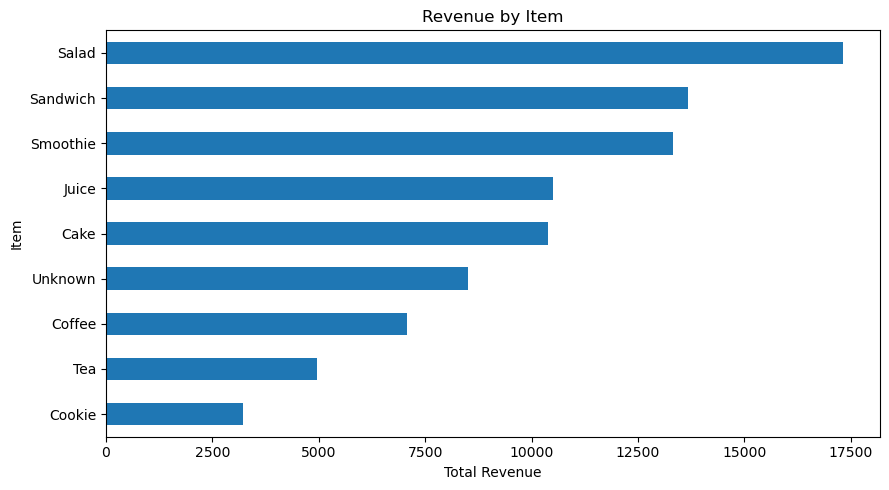

In [4]:
# Revenue by Item
revenue_by_item.sort_values().plot(
    kind="barh",
    figsize=(9, 5),
    title="Revenue by Item"
)

plt.xlabel("Total Revenue")
plt.ylabel("Item")
plt.tight_layout()
plt.show()

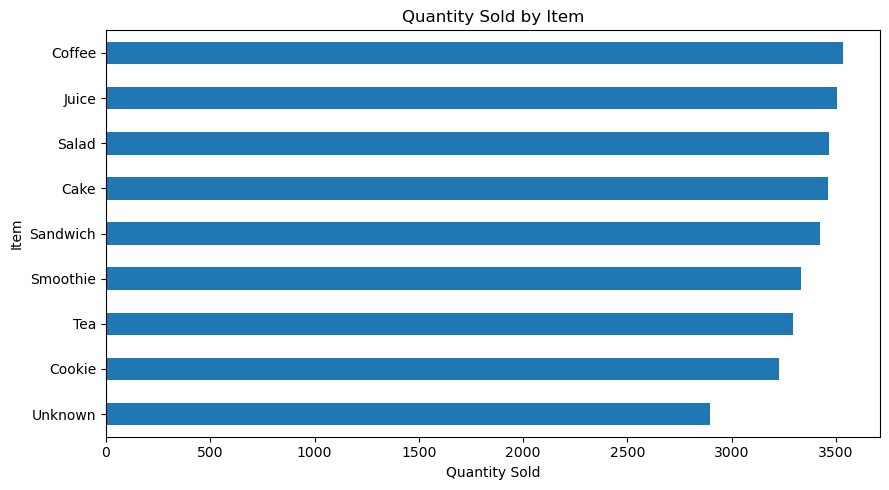

In [5]:
# Quantity Sold by Item
quantity_by_item.sort_values().plot(
    kind="barh",
    figsize=(9, 5),
    title="Quantity Sold by Item"
)

plt.xlabel("Quantity Sold")
plt.ylabel("Item")
plt.tight_layout()
plt.show()

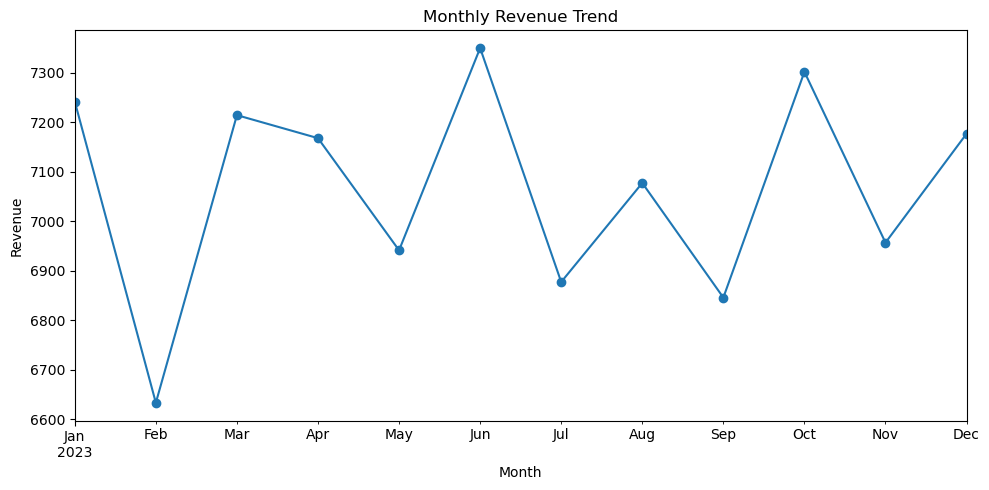

In [6]:
# Convert transaction date to datetime
df["Transaction Date"] = pd.to_datetime(
    df["Transaction Date"],
    errors="coerce"
)

# Calculate monthly revenue
monthly_revenue = (
    df.dropna(subset=["Transaction Date"])
      .set_index("Transaction Date")["Total Spent"]
      .resample("ME")
      .sum()
)

monthly_revenue.plot(
    figsize=(10, 5),
    marker="o",
    title="Monthly Revenue Trend"
)

plt.xlabel("Month")
plt.ylabel("Revenue")
plt.tight_layout()
plt.show()

In [7]:
print("Transactions by Payment Method:")
display(df["Payment Method"].value_counts(dropna=False).to_frame("Transactions"))

print("\nRevenue by Location:")
display(
    df.groupby("Location", dropna=False)["Total Spent"]
      .sum()
      .sort_values(ascending=False)
      .to_frame("Revenue")
)

Transactions by Payment Method:


,Transactions
Payment Method,
Unknown,3178
Digital Wallet,2291
Credit Card,2273
Cash,2258



Revenue by Location:


,Revenue
Location,
Unknown,35337.5
In-store,27127.0
Takeaway,26487.5


# Key Business Insights

This section summarizes the main findings from the cafe sales analysis.

In [8]:
# Key Business Insights

top_revenue_item = revenue_by_item.idxmax()
top_revenue = revenue_by_item.max()

top_quantity_item = quantity_by_item.idxmax()
top_quantity = quantity_by_item.max()

print(f"Highest revenue item: {top_revenue_item} (Revenue: {top_revenue:.2f})")
print(f"Most sold item: {top_quantity_item} (Quantity: {top_quantity})")

print("\nMonthly Revenue Summary:")
display(monthly_revenue.to_frame("Revenue"))

print("\nData Quality Summary:")
print("Total rows:", len(df))
print("Duplicate rows:", df.duplicated().sum())
print("Missing values:", int(df.isnull().sum().sum()))

Highest revenue item: Salad (Revenue: 17320.00)
Most sold item: Coffee (Quantity: 3534.0)

Monthly Revenue Summary:


,Revenue
Transaction Date,
2023-01-31,7242.0
2023-02-28,6633.5
2023-03-31,7214.5
2023-04-30,7168.0
2023-05-31,6941.5
2023-06-30,7350.0
2023-07-31,6877.5
2023-08-31,7077.5
2023-09-30,6846.0



Data Quality Summary:
Total rows: 10000
Duplicate rows: 0
Missing values: 576
